# TC3-46 — Análise de Relações entre Variáveis

**Objetivo:** investigar associações entre as variáveis da base consolidada e o target `alfabetizado`, utilizando análises e visualizações adequadas aos tipos de dados.

**Escopo deste notebook**
- Ler a base consolidada particionada por UF, sem juntar manualmente os arquivos.
- Verificar estrutura, tipos, valores ausentes e distribuição do target.
- Explorar relações entre variáveis numéricas e entre variáveis selecionadas e o target.
- Explorar relações com variáveis categóricas de baixa cardinalidade.
- Registrar achados e limitações para apoiar a próxima etapa de modelagem.

**Cuidados metodológicos**
- Associação não implica causalidade.
- Correlação linear não captura todos os tipos de relação.
- Identificadores (`id_aluno`, `id_escola`, `id_municipio`, quando presentes) não devem ser interpretados automaticamente como variáveis explicativas.
- Variáveis construídas com informação do próprio target ou do mesmo período podem gerar *data leakage*. Os resultados deste notebook são exploratórios, não uma aprovação automática das variáveis para treinamento.
- Como a base tem milhões de linhas, algumas visualizações usam amostra e as agregações são feitas antes de plotar.


## 1. Preparação do ambiente

O notebook usa Polars para consultar os arquivos Parquet de forma eficiente e Polars/matplotlib/seaborn para tabelas e visualizações. Se alguma biblioteca não estiver instalada, instale-a no ambiente do projeto antes de continuar.


## Inicialização independente

Esta célula reproduz a configuração compartilhada do notebook principal. Ela prepara ambiente, caminhos e funções comuns sem alterar a lógica canônica desta etapa.


In [1]:
# =============================================================================
# CONFIGURAÇÕES PARA RODAR O NOTEBOOK
# Execute esta célula primeiro. Esta política não altera a metodologia do fluxo.
# =============================================================================
import os
import sys
import gc
import ctypes
import polars as pl
from datetime import datetime, timezone

# Opções do usuário
PERFIL_RECURSOS = "auto"       # auto | baixo | medio | normal | alto
LIMITE_RAM_PERCENTUAL = None    # None = automático; ou inteiro entre 50 e 90
MAX_THREADS = None              # None = automático; ou inteiro >= 1
USAR_GPU = os.getenv("TC3_USAR_GPU", "1").strip().lower() in {"1", "true", "sim", "yes"}                 # requer WSL2 + RAPIDS/cuML + kernel tc3-gpu

REUTILIZAR_ARTEFATOS = False  # False reconstrói; True aceita caches válidos
SALVAR_ARTEFATOS = True       # False usa somente área temporária da sessão


# Protocolo metodologico compartilhado por todas as fases e modelos.
SEED_GLOBAL = 42
EXECUTAR_SHAP = os.getenv("TC3_EXECUTAR_SHAP", "0").strip().lower() in {"1", "true", "sim", "yes"}
AMOSTRA_SHAP = max(20, int(os.getenv("TC3_AMOSTRA_SHAP", "100")))
AMOSTRA_BACKGROUND_SHAP = max(20, int(os.getenv("TC3_BACKGROUND_SHAP", "50")))
CHAVE_GRUPO_GLOBAL = "chave_escola_ano"
N_SPLITS_CV_GLOBAL = 3
N_ITER_BUSCA_GLOBAL = 10
LIMIAR_CLASSIFICACAO_GLOBAL = 0.50
REPETICOES_PERMUTACAO_GLOBAL = 5
REPETICOES_BOOTSTRAP_GLOBAL = 200

N_JOBS_MODELAGEM_GLOBAL = 1
N_SPLITS_HOLDOUT_GLOBAL = 1
SCORING_PRINCIPAL_GLOBAL = "roc_auc"
VERBOSE_BUSCA_GLOBAL = 2
ERRO_BUSCA_GLOBAL = "raise"
RETORNAR_SCORE_TREINO_GLOBAL = True

# Contrato comum de pre-processamento dos modelos.
IMPUTACAO_NUMERICA_GLOBAL = "median"
IMPUTACAO_CATEGORICA_GLOBAL = "most_frequent"
ONE_HOT_DESCONHECIDO_GLOBAL = "ignore"
ONE_HOT_SPARSO_GLOBAL = False  # matriz densa: evita fallback dos modelos para CPU
SPARSE_THRESHOLD_GLOBAL = 0.0
ESCALONADOR_CENTRALIZAR_GLOBAL = False


# Percentuais de amostragem (0 < valor <= 1). Alterar aqui afeta todo o notebook.
# O teste final permanece integral (100%); as amostras menores servem apenas ao
# desenvolvimento, comparacao de modelos e interpretabilidade.
FRACOES_AMOSTRAGEM = {
    "eda_correlacao": 0.05,
    "validacao_preparacao": 0.02,
    "fase5_modelos": 0.10,
    "fase5_knn": 0.02,  # KNN tem custo de memoria e predicao maior.
    "fase6_desenvolvimento": 0.12,
    "fase6_validacao_interna": 0.25,
    "fase7_desenvolvimento": 1.00,
    "fase7_teste": 1.00,
    "interpretacao": 0.035,
    "bootstrap": 0.17,
}

for _nome, _fracao in FRACOES_AMOSTRAGEM.items():
    if not 0 < _fracao <= 1:
        raise ValueError(f"Fracao invalida em FRACOES_AMOSTRAGEM[{_nome!r}]: {_fracao}")


def tamanho_por_fracao(total, fracao):
    """Converte uma proporcao em quantidade reproduzivel, sem exceder o total."""
    if total < 1:
        raise ValueError("Nao e possivel amostrar uma particao vazia.")
    return min(total, max(1, round(total * fracao)))


def materializar_split_percentual(dados, contrato, nome_split, fracao, seed, materializador):
    """Materializa uma fracao de um split e informa claramente o universo usado."""
    import polars as pl

    coluna_split = contrato["controle_split"]
    total = (
        dados.filter(pl.col(coluna_split) == nome_split)
        .select(pl.len().alias("total"))
        .collect()
        .item()
    )
    quantidade = tamanho_por_fracao(total, fracao)
    X, y = materializador(dados, contrato, nome_split, limit=quantidade, seed=seed)
    print(f"{nome_split}: {quantidade:,}/{total:,} registros ({fracao:.1%})")
    return X, y


def _estado_memoria_sistema():
    """Retorna RAM total e disponível em bytes."""
    valores = {}
    try:
        with open("/proc/meminfo", encoding="utf-8") as arquivo:
            for linha in arquivo:
                chave, valor = linha.split(":", 1)
                valores[chave] = int(valor.strip().split()[0]) * 1024
        return valores["MemTotal"], valores.get("MemAvailable", valores.get("MemFree", 0))
    except (OSError, KeyError, ValueError):
        try:
            return (
                os.sysconf("SC_PHYS_PAGES") * os.sysconf("SC_PAGE_SIZE"),
                os.sysconf("SC_AVPHYS_PAGES") * os.sysconf("SC_PAGE_SIZE"),
            )
        except (AttributeError, OSError, ValueError):
            return None, None


RAM_TOTAL_BYTES, RAM_DISPONIVEL_BYTES = _estado_memoria_sistema()
RAM_TOTAL_GB = RAM_TOTAL_BYTES / 1024**3 if RAM_TOTAL_BYTES else 0.0
CPUS_LOGICAS = os.cpu_count() or 1

if RAM_TOTAL_GB and RAM_TOTAL_GB <= 4.5:
    _perfil_detectado = "baixo"
elif RAM_TOTAL_GB and RAM_TOTAL_GB <= 8.5:
    _perfil_detectado = "medio"
elif RAM_TOTAL_GB and RAM_TOTAL_GB <= 16.5:
    _perfil_detectado = "normal"
else:
    _perfil_detectado = "alto"

_perfis = {
    "baixo": (60, 1),
    "medio": (70, min(2, CPUS_LOGICAS)),
    "normal": (75, min(4, CPUS_LOGICAS)),
    "alto": (80, min(8, max(1, CPUS_LOGICAS // 2))),
}
PERFIL_ATIVO = _perfil_detectado if PERFIL_RECURSOS == "auto" else PERFIL_RECURSOS.lower()
if PERFIL_ATIVO not in _perfis:
    raise ValueError("PERFIL_RECURSOS deve ser auto, baixo, medio, normal ou alto.")

_limite_perfil, _threads_perfil = _perfis[PERFIL_ATIVO]
LIMITE_RAM_ATIVO = _limite_perfil if LIMITE_RAM_PERCENTUAL is None else int(LIMITE_RAM_PERCENTUAL)
THREADS_MAXIMAS = _threads_perfil if MAX_THREADS is None else int(MAX_THREADS)
if not 50 <= LIMITE_RAM_ATIVO <= 90:
    raise ValueError("LIMITE_RAM_PERCENTUAL deve ficar entre 50 e 90.")
if THREADS_MAXIMAS < 1:
    raise ValueError("MAX_THREADS deve ser pelo menos 1.")
THREADS_MAXIMAS = min(THREADS_MAXIMAS, CPUS_LOGICAS)

# Definido antes de NumPy, Polars, scikit-learn e cuML serem importados.
for _variavel, _valor in {
    "OMP_NUM_THREADS": str(THREADS_MAXIMAS),
    "OPENBLAS_NUM_THREADS": str(THREADS_MAXIMAS),
    "MKL_NUM_THREADS": str(THREADS_MAXIMAS),
    "NUMEXPR_NUM_THREADS": str(THREADS_MAXIMAS),
    "VECLIB_MAXIMUM_THREADS": str(THREADS_MAXIMAS),
    "POLARS_MAX_THREADS": str(THREADS_MAXIMAS),
    "MALLOC_ARENA_MAX": "2",
}.items():
    os.environ[_variavel] = _valor

HISTORICO_RECURSOS = []
_estado_recursos = {"nivel": None, "threads": None, "contexto_threads": None}


def _aplicar_threads(limite):
    """Limita pools BLAS/OpenMP já carregados; Polars usa o limite inicial."""
    limite = max(1, min(int(limite), THREADS_MAXIMAS))
    if _estado_recursos["threads"] == limite:
        return
    anterior = _estado_recursos.get("contexto_threads")
    if anterior is not None:
        try:
            anterior.__exit__(None, None, None)
        except Exception:
            pass
    try:
        from threadpoolctl import threadpool_limits
        contexto = threadpool_limits(limits=limite)
        contexto.__enter__()
    except Exception:
        contexto = None
    _estado_recursos["contexto_threads"] = contexto
    _estado_recursos["threads"] = limite


def _liberar_memoria_global(agressiva=False):
    """Libera caches transitórios sem apagar variáveis usadas pelo fluxo."""
    shell = get_ipython()
    if shell is not None:
        for nome in ("_", "__", "___"):
            shell.user_ns[nome] = None
    gc.collect()
    modulo_cupy = sys.modules.get("cupy")
    if modulo_cupy is not None:
        try:
            modulo_cupy.get_default_memory_pool().free_all_blocks()
            modulo_cupy.get_default_pinned_memory_pool().free_all_blocks()
        except Exception:
            pass
    if agressiva:
        modulo_plt = sys.modules.get("matplotlib.pyplot")
        if modulo_plt is not None:
            try:
                modulo_plt.close("all")
            except Exception:
                pass
        try:
            ctypes.CDLL("libc.so.6").malloc_trim(0)
        except (OSError, AttributeError):
            pass


def _gerenciar_recursos(*_args, **_kwargs):
    """Reduz paralelismo progressivamente e nunca interrompe uma célula."""
    total, disponivel = _estado_memoria_sistema()
    if not total:
        return
    uso = 100.0 * (total - disponivel) / total
    margem = LIMITE_RAM_ATIVO - uso
    if margem > 15:
        nivel, threads, limpar = "normal", THREADS_MAXIMAS, False
    elif margem > 7:
        nivel, threads, limpar = "moderado", max(1, THREADS_MAXIMAS // 2), True
    else:
        nivel, threads, limpar = "conservador", 1, True

    _aplicar_threads(threads)
    if limpar:
        _liberar_memoria_global(agressiva=margem <= 0)

    if nivel != _estado_recursos["nivel"]:
        registro = {
            "instante_utc": datetime.now(timezone.utc).isoformat(),
            "nivel": nivel,
            "threads": threads,
            "ram_usada_percentual": round(uso, 1),
            "ram_disponivel_gb": round(disponivel / 1024**3, 2),
        }
        HISTORICO_RECURSOS.append(registro)
        print(
            f"[recursos] nível={nivel}; threads={threads}; "
            f"RAM usada={uso:.1f}%; livre={disponivel / 1024**3:.1f} GB."
        )
        _estado_recursos["nivel"] = nivel


ipython = get_ipython()
if ipython is not None:
    # Impede callbacks duplicados ao reexecutar a configuração.
    for _atributo in ("_tc3_memory_guard", "_tc3_resource_guard"):
        _guard_anterior = getattr(ipython, _atributo, None)
        if _guard_anterior is not None:
            for _evento, _funcao in _guard_anterior:
                try:
                    ipython.events.unregister(_evento, _funcao)
                except (ValueError, KeyError):
                    pass
    _callbacks_recursos = [
        ("pre_run_cell", _gerenciar_recursos),
        ("post_run_cell", _gerenciar_recursos),
    ]
    for _evento, _funcao in _callbacks_recursos:
        ipython.events.register(_evento, _funcao)
    ipython._tc3_resource_guard = _callbacks_recursos

_gerenciar_recursos()
print(
    "Configuração automática ativa: "
    f"perfil={PERFIL_ATIVO}; RAM={RAM_TOTAL_GB:.1f} GB; CPUs={CPUS_LOGICAS}; "
    f"limite preventivo={LIMITE_RAM_ATIVO}%; threads máximas={THREADS_MAXIMAS}."
)

# Backend GPU: ativado antes de qualquer importação do scikit-learn.
cuda_conda = os.path.join(sys.prefix, "targets", "x86_64-linux")
if os.path.exists(os.path.join(cuda_conda, "include", "cuda.h")):
    os.environ.setdefault("CUDA_PATH", cuda_conda)
if USAR_GPU:
    try:
        from cuml.accel import install
        install(log_level="info")
        import cupy as cp
        dispositivo = cp.cuda.runtime.getDeviceProperties(0)
        nome_gpu = dispositivo["name"].decode() if isinstance(dispositivo["name"], bytes) else str(dispositivo["name"])
        memoria_gpu_gb = cp.cuda.runtime.memGetInfo()[1] / 1024**3
        BACKEND_ML = f"RAPIDS cuML — {nome_gpu} ({memoria_gpu_gb:.1f} GB de VRAM)"
    except Exception as exc:
        raise RuntimeError("GPU/RAPIDS indisponível. Abra no WSL2 e selecione o kernel tc3-gpu.") from exc
else:
    BACKEND_ML = "scikit-learn CPU"
print("Backend de Machine Learning:", BACKEND_ML)

from pathlib import Path
import hashlib
import json
from urllib.error import HTTPError, URLError
from urllib.request import Request, urlopen

def localizar_raiz(inicio: Path) -> Path:
    for candidato in [inicio, *inicio.parents]:
        if (candidato / "dados").is_dir() and (candidato / "notebooks").is_dir():
            return candidato
    raise FileNotFoundError("Execute este notebook dentro do repositório tech_challenge_3.")

PROJECT_ROOT = localizar_raiz(Path.cwd().resolve())
print("Raiz do projeto:", PROJECT_ROOT)


# Contrato único de diretórios. Fontes sempre são lidas da área imutável.
import tempfile

FONTES_ORIGINAIS_DIR = PROJECT_ROOT / "dados" / "fontes_originais"
_TEMP_BASE = PROJECT_ROOT / ".execucao_temporaria"
_TEMP_BASE.mkdir(parents=True, exist_ok=True)
if SALVAR_ARTEFATOS:
    RAIZ_ARTEFATOS = PROJECT_ROOT
    _DIRETORIO_TEMPORARIO = None
else:
    _DIRETORIO_TEMPORARIO = tempfile.TemporaryDirectory(prefix="tc3_", dir=_TEMP_BASE)
    RAIZ_ARTEFATOS = Path(_DIRETORIO_TEMPORARIO.name)

DADOS_PROCESSADOS_DIR = RAIZ_ARTEFATOS / "dados" / "dados_processados"
DADOS_ANALITICOS_DIR = RAIZ_ARTEFATOS / "dados" / "dados_analiticos"
RESULTADOS_DIR = RAIZ_ARTEFATOS / "resultados"
RESULTADOS_FIGURAS_DIR = RESULTADOS_DIR / "figuras"
RESULTADOS_TABELAS_DIR = RESULTADOS_DIR / "tabelas"
RESULTADOS_METRICAS_DIR = RESULTADOS_DIR / "metricas"
RESULTADOS_RELATORIOS_DIR = RESULTADOS_DIR / "relatorios"
MODELOS_DIR = RAIZ_ARTEFATOS / "modelos"

for _diretorio_saida in (
    DADOS_PROCESSADOS_DIR, DADOS_ANALITICOS_DIR, RESULTADOS_FIGURAS_DIR,
    RESULTADOS_TABELAS_DIR, RESULTADOS_METRICAS_DIR,
    RESULTADOS_RELATORIOS_DIR, MODELOS_DIR,
):
    _diretorio_saida.mkdir(parents=True, exist_ok=True)

def deve_recalcular(caminho):
    """True quando o cache deve ser ignorado ou ainda não existe."""
    return not REUTILIZAR_ARTEFATOS or not Path(caminho).exists()


def publicar_parquet_particionado(frame, destino, *, particionar_por):
    """Publica partições sequencialmente e troca o diretório de forma atômica.

    O ``write_parquet(partition_by=...)`` do Polars prepara várias partições em
    paralelo e pode duplicar o pico de RAM de bases já materializadas. Esta
    implementação mantém apenas uma partição adicional em memória por vez.
    """
    import gc
    import shutil

    destino = Path(destino)
    temporario = destino.with_name(destino.name + "__publicacao_tmp")
    anterior = destino.with_name(destino.name + "__publicacao_anterior")
    for caminho in (temporario, anterior):
        if caminho.exists():
            shutil.rmtree(caminho)
    temporario.mkdir(parents=True, exist_ok=True)

    lazy = frame if isinstance(frame, pl.LazyFrame) else frame.lazy()
    schema = lazy.collect_schema()
    if particionar_por not in schema.names():
        raise ValueError(f"Coluna de particionamento ausente: {particionar_por}")

    valores = (
        lazy.select(pl.col(particionar_por).unique())
        .collect(engine="streaming")
        .get_column(particionar_por)
        .to_list()
    )
    valores = sorted(valores, key=lambda valor: (valor is None, str(valor)))
    if not valores:
        raise RuntimeError("Não há valores para particionar a publicação.")

    arquivos_novos = []
    for indice, valor in enumerate(valores):
        valor_hive = "__HIVE_DEFAULT_PARTITION__" if valor is None else str(valor)
        if any(separador in valor_hive for separador in ("/", "\\")):
            raise ValueError(f"Valor de partição inválido: {valor_hive!r}")
        diretorio_particao = temporario / f"{particionar_por}={valor_hive}"
        diretorio_particao.mkdir(parents=True, exist_ok=True)
        arquivo = diretorio_particao / f"part-{indice:05d}.parquet"
        predicado = pl.col(particionar_por).is_null() if valor is None else pl.col(particionar_por) == pl.lit(valor)
        lazy.filter(predicado).sink_parquet(
            arquivo,
            compression="zstd",
            statistics=True,
            row_group_size=100_000,
            mkdir=True,
            engine="streaming",
        )
        if not arquivo.is_file() or arquivo.stat().st_size == 0:
            raise RuntimeError(f"Partição não foi gravada corretamente: {arquivo}")
        arquivos_novos.append(arquivo)
        gc.collect()

    if destino.exists():
        destino.replace(anterior)
    try:
        try:
            temporario.replace(destino)
        except OSError:
            # Volumes Docker montados do Windows podem bloquear rename de diretórios.
            # O fallback copia a publicação pronta e remove a área temporária.
            shutil.copytree(temporario, destino)
            shutil.rmtree(temporario)
    except Exception:
        if destino.exists():
            shutil.rmtree(destino)
        if anterior.exists():
            anterior.replace(destino)
        raise
    if anterior.exists():
        shutil.rmtree(anterior)
    return len(arquivos_novos)


def salvar_figura_eda(figura, nome):
    """Exporta uma figura exploratória sem alterar sua exibição no notebook."""
    destino = RESULTADOS_FIGURAS_DIR / "fluxo_exploratorio" / nome
    destino.parent.mkdir(parents=True, exist_ok=True)
    figura.savefig(destino, dpi=180, bbox_inches="tight")
    return destino

print("Fontes originais:", FONTES_ORIGINAIS_DIR)
print("Destino dos artefatos:", RAIZ_ARTEFATOS)
print("Reutilizar artefatos:", REUTILIZAR_ARTEFATOS, "| Salvar:", SALVAR_ARTEFATOS)

# Imports compartilhados que, no fluxo completo, são carregados por etapas anteriores.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display


[recursos] nível=normal; threads=4; RAM usada=30.3%; livre=10.8 GB.
Configuração automática ativa: perfil=normal; RAM=15.5 GB; CPUs=20; limite preventivo=75%; threads máximas=4.
[cuml.accel] Accelerator installed.
Backend de Machine Learning: RAPIDS cuML — NVIDIA GeForce RTX 3050 6GB Laptop GPU (6.0 GB de VRAM)
Raiz do projeto: /workspace
Fontes originais: /workspace/dados/fontes_originais
Destino dos artefatos: /workspace
Reutilizar artefatos: False | Salvar: True


In [2]:
from pathlib import Path
import warnings

import polars as pl
import numpy as np
import matplotlib.pyplot as plt

plt.style.use("seaborn-v0_8-whitegrid")

print("Polars:", pl.__version__)


Polars: 2.0.0


## 2. Localização e leitura dos arquivos

A estrutura esperada é:

`dados/dados_processados/consolidado/base_alunos_municipios_por_uf/sigla_uf=SP/*.parquet`

O código procura a pasta a partir do diretório atual e de seus diretórios pais. Se estiver executando o notebook fora da raiz do repositório, ajuste `PROJECT_ROOT` manualmente.


In [3]:
# Usa o diretório processado ativo, persistente ou temporário.
BASE_PATH = DADOS_PROCESSADOS_DIR / "consolidado" / "base_alunos_municipios_por_uf"

arquivos_parquet = sorted(BASE_PATH.glob("sigla_uf=*/*.parquet"))

print("Raiz do projeto:", PROJECT_ROOT)
print("Pasta da base:", BASE_PATH)
print("Quantidade de arquivos Parquet:", len(arquivos_parquet))
print("Exemplos:", [str(p.relative_to(PROJECT_ROOT)) for p in arquivos_parquet[:5]])

if not arquivos_parquet:
    raise FileNotFoundError(f"Nenhum Parquet encontrado em {BASE_PATH}")

# Lazy scan: o Polars consulta os arquivos sem carregar tudo imediatamente.
lf = pl.scan_parquet(
    [str(p) for p in arquivos_parquet],
    hive_partitioning=True
)

print("Esquema detectado:")
print(lf.collect_schema())

Raiz do projeto: /workspace
Pasta da base: /workspace/dados/dados_processados/consolidado/base_alunos_municipios_por_uf
Quantidade de arquivos Parquet: 26
Exemplos: ['dados/dados_processados/consolidado/base_alunos_municipios_por_uf/sigla_uf=AC/part-00000.parquet', 'dados/dados_processados/consolidado/base_alunos_municipios_por_uf/sigla_uf=AL/part-00001.parquet', 'dados/dados_processados/consolidado/base_alunos_municipios_por_uf/sigla_uf=AM/part-00002.parquet', 'dados/dados_processados/consolidado/base_alunos_municipios_por_uf/sigla_uf=AP/part-00003.parquet', 'dados/dados_processados/consolidado/base_alunos_municipios_por_uf/sigla_uf=BA/part-00004.parquet']
Esquema detectado:
Schema({'id_aluno': String, 'id_escola': String, 'id_municipio': Int64, 'nome_municipio': String, 'sigla_uf': String, 'ano_referencia': Int64, 'serie': Int32, 'rede': Int32, 'rede_descricao': String, 'caderno': String, 'presenca': Int32, 'preenchimento_caderno': Int32, 'proficiencia': Float64, 'peso_aluno': Float6

## 3. Dimensão e visão geral

Esta célula calcula a quantidade de registros e colunas. Pode levar algum tempo, pois consulta todos os arquivos.


In [4]:
resumo_dimensoes = lf.select(pl.len().alias("registros"), pl.lit(len(lf.collect_schema().names())).alias("colunas")).collect()
display(resumo_dimensoes)


registros,colunas
u32,i32
3867999,49


## 4. Tipos de dados e valores ausentes

A tabela de nulos ajuda a identificar variáveis que exigem cuidado. Percentuais altos de nulos podem refletir cobertura desigual entre anos/fontes, mas essa hipótese deve ser conferida com a documentação e as regras de construção da base.


In [5]:
schema = lf.collect_schema()
inventario_tipos = pl.DataFrame({"variavel": schema.names(), "tipo": [str(schema[n]) for n in schema.names()]})
display(inventario_tipos)
nulos = lf.select([pl.col(c).null_count().alias(c) for c in schema.names()]).collect().row(0, named=True)
total_registros = resumo_dimensoes["registros"].item()
tabela_nulos = pl.DataFrame({"variavel": list(nulos), "nulos": list(nulos.values())}).with_columns(
    (100*pl.col("nulos")/total_registros).alias("percentual_nulos")
).sort("percentual_nulos", descending=True)
display(tabela_nulos)


variavel,tipo
str,str
"""id_aluno""","""String"""
"""id_escola""","""String"""
"""id_municipio""","""Int64"""
"""nome_municipio""","""String"""
"""sigla_uf""","""String"""
…,…
"""in_agua_rede_publica""","""Float64"""
"""in_energia_rede_publica""","""Float64"""
"""in_esgoto_rede_publica""","""Float64"""


variavel,nulos,percentual_nulos
str,i64,f64
"""taxa_alfabetizacao_municipio_a…",1791646,46.319712
"""media_portugues_municipio_ano_…",1791646,46.319712
"""proficiencia""",513338,13.27141
"""peso_aluno""",513338,13.27141
"""valor_receitas""",34500,0.891934
…,…,…
"""in_agua_rede_publica""",0,0.0
"""in_energia_rede_publica""",0,0.0
"""in_esgoto_rede_publica""",0,0.0


## 5. Distribuição do target `alfabetizado`

Confirme se o target existe e quais valores foram observados. Espera-se uma variável binária, mas o notebook não assume antecipadamente a codificação sem conferir os dados.


alfabetizado,quantidade,percentual
i32,u32,f64
0,1883453,48.693213
1,1984546,51.306787


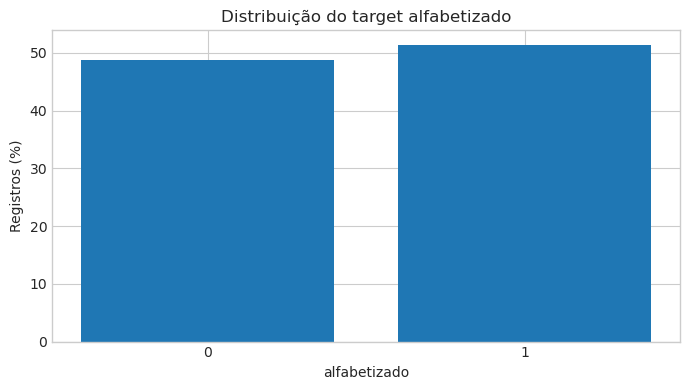

In [6]:
COL_TARGET="alfabetizado"
if COL_TARGET not in schema.names(): raise KeyError(f"Target {COL_TARGET!r} não encontrado.")
dist_target=(lf.group_by(COL_TARGET).agg(pl.len().alias("quantidade")).sort(COL_TARGET).collect()
 .with_columns((100*pl.col("quantidade")/pl.col("quantidade").sum()).alias("percentual")))
display(dist_target)
plt.figure(figsize=(7,4)); plt.bar(dist_target[COL_TARGET].cast(pl.String).to_list(),dist_target["percentual"].to_numpy())
plt.title("Distribuição do target alfabetizado"); plt.ylabel("Registros (%)"); plt.xlabel("alfabetizado"); plt.tight_layout(); salvar_figura_eda(plt.gcf(),"193_5_distribuicao_do_target_alfabetizado_01.png"); plt.show()


## 6. Separação inicial das variáveis

A separação abaixo é automática e serve como ponto de partida. Revise a lista antes de interpretar os resultados: algumas colunas numéricas são códigos, identificadores ou variáveis de controle, e não medidas quantitativas apropriadas para correlação.


In [7]:
colunas = schema.names()
identificadores = [
    c for c in colunas
    if c.lower() in {"id_aluno", "id_escola", "id_municipio", "codigo_do_municipio",
                     "cod_municipio", "sigla_uf", "nome_uf", "nome_do_municipio"}
]
colunas_numericas = [
    nome for nome, dtype in schema.items()
    if dtype.is_numeric() and nome != COL_TARGET
]
colunas_categoricas = [
    nome for nome, dtype in schema.items()
    if dtype == pl.String or dtype == pl.Categorical or dtype == pl.Enum
]

print("Target:", COL_TARGET)
print("Identificadores/códigos candidatos a exclusão das correlações:", identificadores)
print("Variáveis numéricas detectadas:", colunas_numericas)
print("Variáveis categóricas detectadas:", colunas_categoricas)


Target: alfabetizado
Identificadores/códigos candidatos a exclusão das correlações: ['id_aluno', 'id_escola', 'id_municipio', 'sigla_uf']
Variáveis numéricas detectadas: ['id_municipio', 'ano_referencia', 'serie', 'rede', 'presenca', 'preenchimento_caderno', 'proficiencia', 'peso_aluno', 'taxa_alfabetizacao_municipio_ano_anterior', 'media_portugues_municipio_ano_anterior', 'valor_bolsa_familia', 'valor_fundeb', 'valor_receitas', 'valor_pib', 'valor_pib_per_capita', 'qtd_escolas_inse', 'qtd_alunos_inse', 'media_inse', 'pc_nivel_1', 'pc_nivel_2', 'pc_nivel_3', 'pc_nivel_4', 'pc_nivel_5', 'pc_nivel_6', 'pc_nivel_7', 'pc_nivel_8', 'qtd_escolas_censo', 'qt_mat_bas', 'qt_doc_bas', 'qt_tur_bas', 'in_biblioteca_sala_leitura', 'in_laboratorio_informatica', 'in_quadra_esportes', 'in_agua_rede_publica', 'in_energia_rede_publica', 'in_esgoto_rede_publica', 'in_internet', 'in_banda_larga']
Variáveis categóricas detectadas: ['id_aluno', 'id_escola', 'nome_municipio', 'sigla_uf', 'rede_descricao', 'c

## 7. Correlação entre variáveis numéricas

Calculamos a matriz em uma amostra aleatória de até 150 mil registros para manter a análise leve. A correlação de Pearson identifica principalmente relações lineares; não prova causalidade e pode ser influenciada por assimetria e valores extremos.

**Atenção:** a seleção exclui identificadores óbvios, mas revise os nomes impressos na seção anterior e ajuste `excluir_da_correlacao` conforme o dicionário da base.


Registros na amostra: 192850


variavel,valores_disponiveis
str,u32
"""taxa_alfabetizacao_municipio_a…",103684
"""media_portugues_municipio_ano_…",103684
"""proficiencia""",167165
"""peso_aluno""",167165
"""valor_receitas""",191168
…,…
"""in_agua_rede_publica""",192850
"""in_energia_rede_publica""",192850
"""in_esgoto_rede_publica""",192850


/opt/conda/lib/python3.12/site-packages/numpy/lib/_function_base_impl.py:3045: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
/opt/conda/lib/python3.12/site-packages/numpy/lib/_function_base_impl.py:3046: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


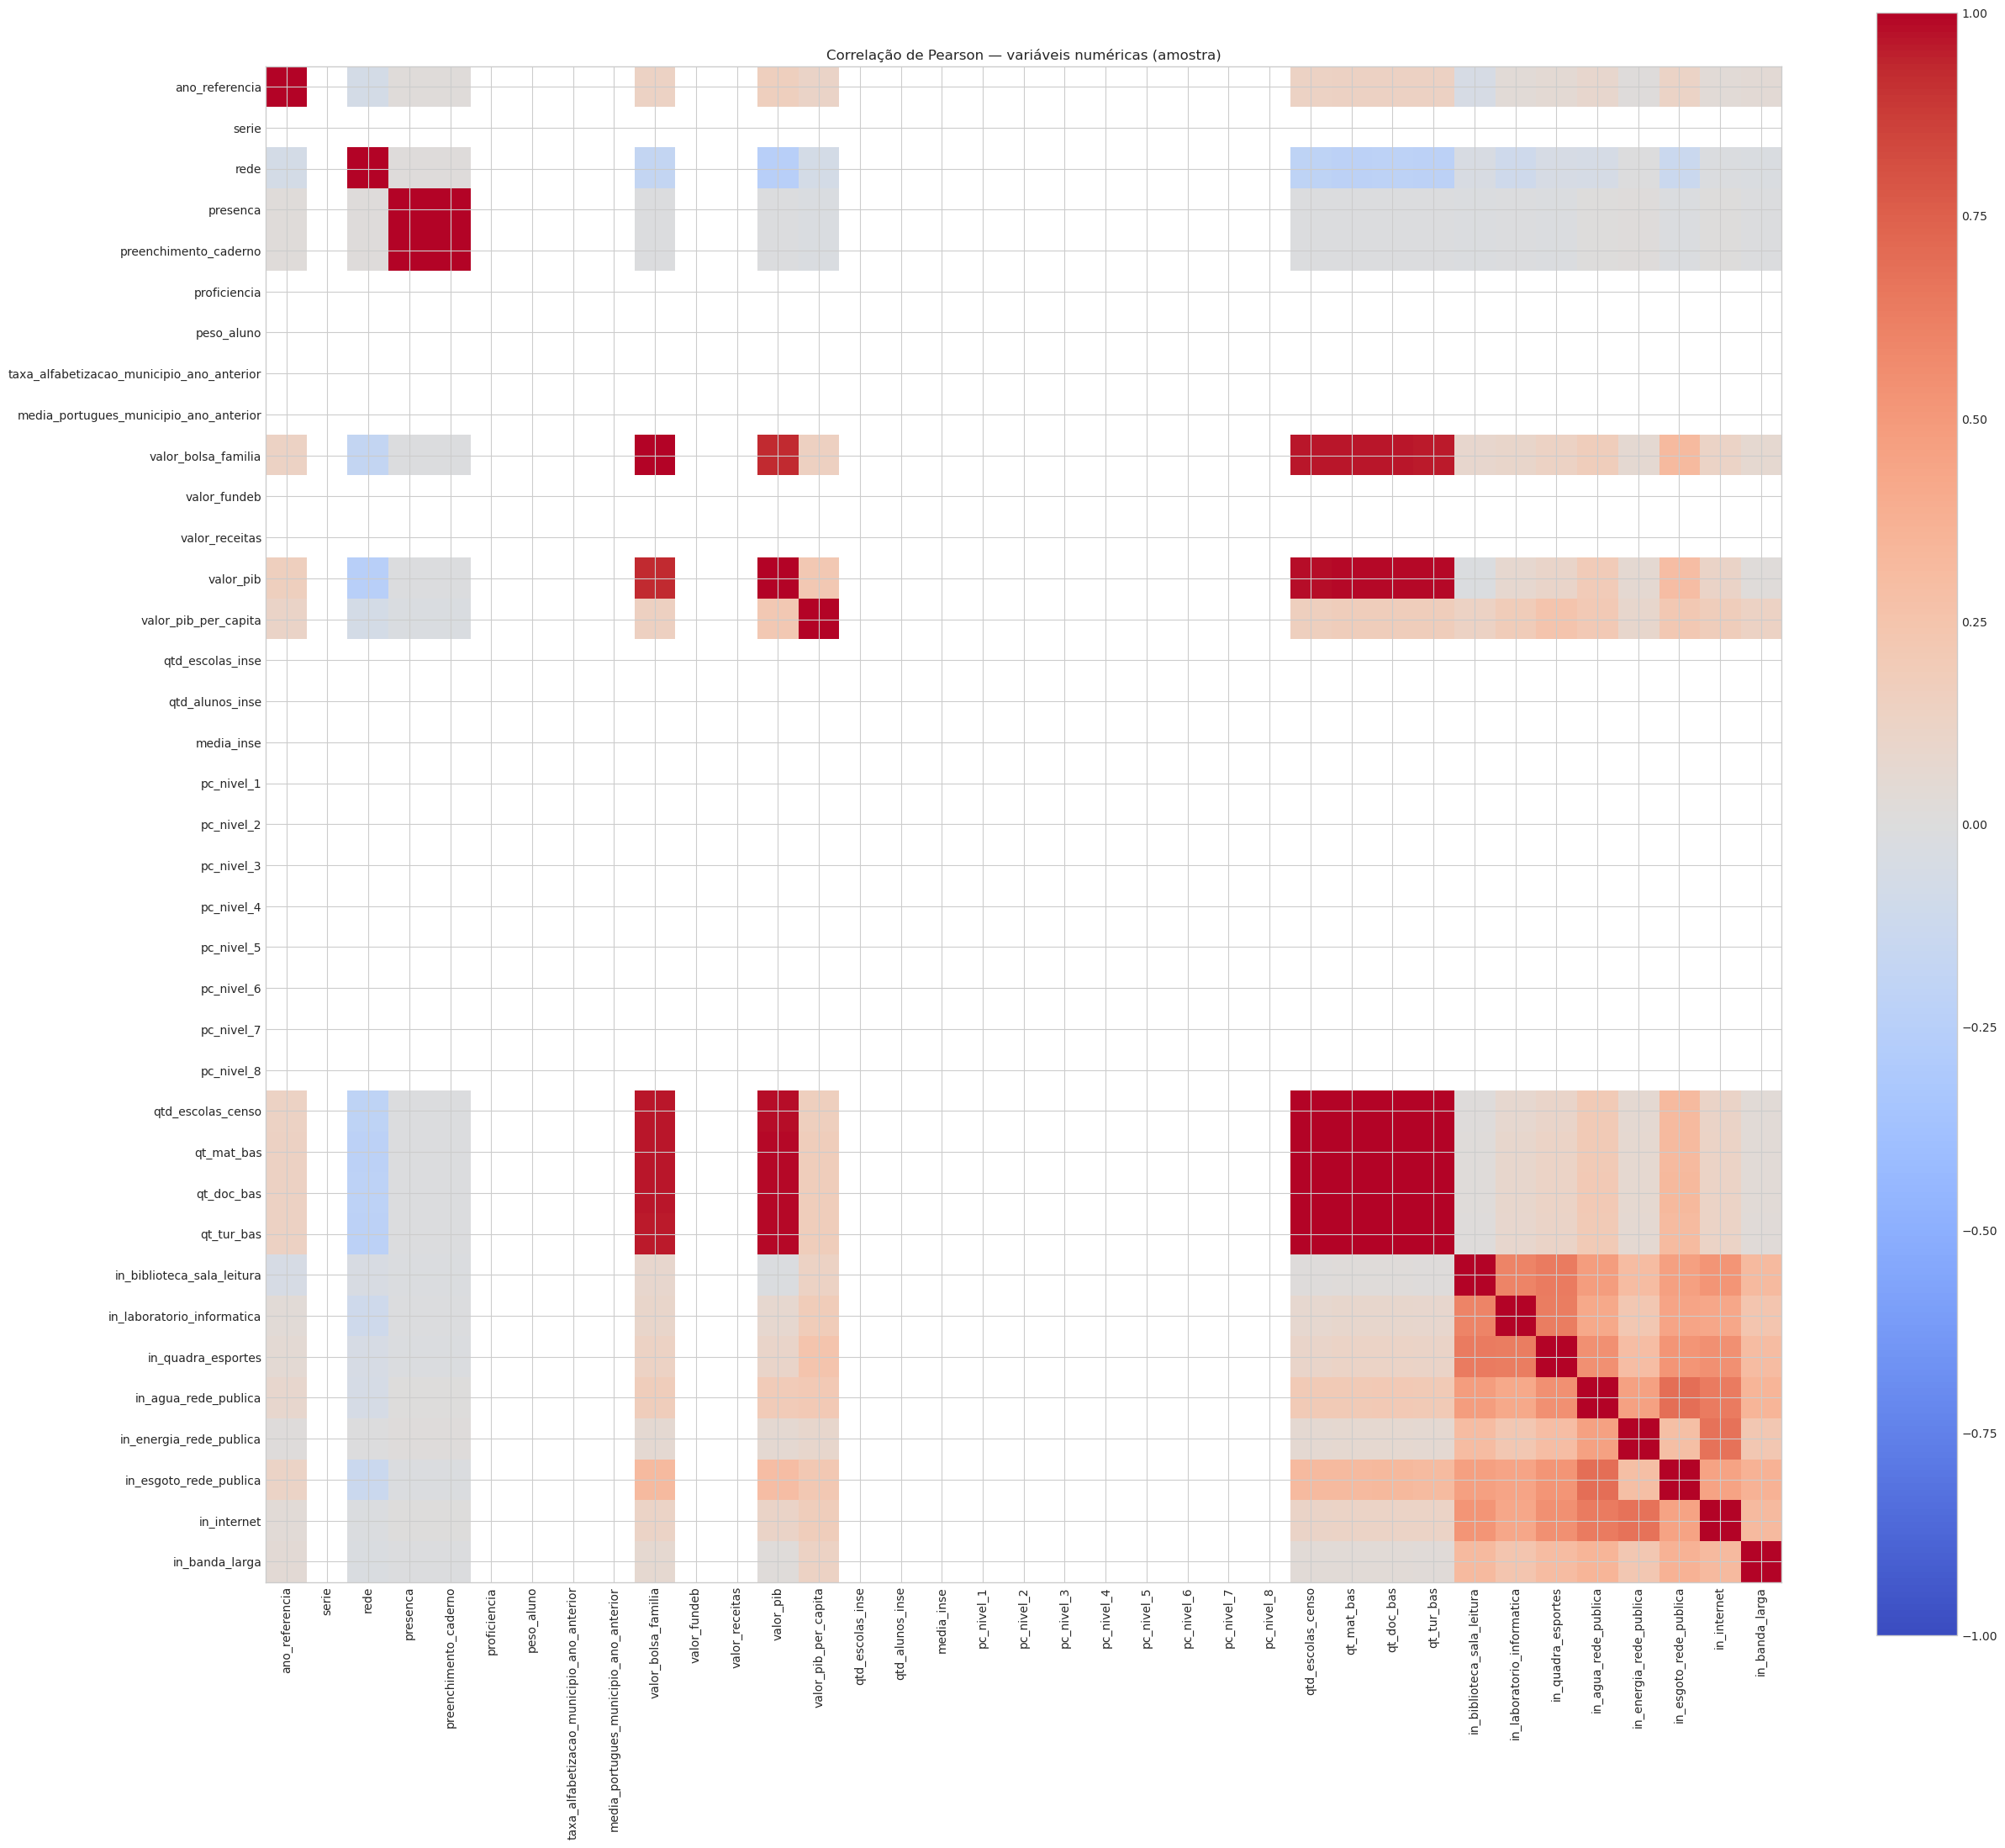

variavel_1,variavel_2,correlacao,correlacao_abs
str,str,f64,f64
"""qt_mat_bas""","""qt_tur_bas""",0.999257,0.999257
"""qt_mat_bas""","""qt_doc_bas""",0.998772,0.998772
"""presenca""","""preenchimento_caderno""",0.998607,0.998607
"""qtd_escolas_censo""","""qt_doc_bas""",0.998464,0.998464
"""qt_doc_bas""","""qt_tur_bas""",0.998451,0.998451
…,…,…,…
"""valor_bolsa_familia""","""valor_pib""",0.922268,0.922268
"""in_agua_rede_publica""","""in_esgoto_rede_publica""",0.691332,0.691332
"""in_energia_rede_publica""","""in_internet""",0.676361,0.676361


In [8]:
FRACAO_AMOSTRA=FRACOES_AMOSTRAGEM["eda_correlacao"]
excluir_da_correlacao=set(identificadores)|{COL_TARGET}; numericas_correlacao=[c for c in colunas_numericas if c not in excluir_da_correlacao]
if len(numericas_correlacao)<2: print("Não há variáveis numéricas suficientes para calcular correlações.")
else:
    limite_hash=max(1,round(FRACAO_AMOSTRA*10_000))
    df_corr=(lf.filter((pl.col("id_aluno").hash(seed=SEED_GLOBAL)%10_000)<limite_hash).select(numericas_correlacao).collect(engine="streaming"))
    print("Registros na amostra:",df_corr.height); display(df_corr.select([pl.col(c).count().alias(c) for c in numericas_correlacao]).unpivot(variable_name="variavel",value_name="valores_disponiveis").sort("valores_disponiveis"))
    matriz_corr=df_corr.corr(); nomes=matriz_corr.columns; valores=matriz_corr.to_numpy()
    plt.figure(figsize=(max(10,len(nomes)*.7),max(8,len(nomes)*.6))); plt.imshow(valores,cmap="coolwarm",vmin=-1,vmax=1); plt.colorbar(); plt.xticks(range(len(nomes)),nomes,rotation=90); plt.yticks(range(len(nomes)),nomes); plt.title("Correlação de Pearson — variáveis numéricas (amostra)"); plt.tight_layout(); salvar_figura_eda(plt.gcf(),"197_7_correlacao_entre_variaveis_numericas_01.png"); plt.show()
    pares=pl.DataFrame([{"variavel_1":nomes[a],"variavel_2":nomes[b],"correlacao":float(valores[a,b])} for a in range(len(nomes)) for b in range(a+1,len(nomes)) if np.isfinite(valores[a,b])]).with_columns(pl.col("correlacao").abs().alias("correlacao_abs")).sort("correlacao_abs",descending=True)
    display(pares.head(20))


## 8. Relação entre variáveis numéricas e o target

Quando o target é binário (0/1), a correlação ponto-bisserial equivale à correlação de Pearson entre a variável numérica e o target codificado numericamente. Aqui apresentamos a correlação como triagem exploratória, desde que os valores do target sejam realmente binários.

Correlação próxima de zero não exclui uma relação não linear. Variáveis com muitos nulos também podem apresentar resultados enviesados se a análise considerar apenas linhas completas.


Valores distintos do target: [1, 0]


variavel,correlacao_com_target,abs_correlacao
str,f64,f64
"""serie""",NaN,NaN
"""proficiencia""",0.795599,0.795599
"""preenchimento_caderno""",0.401542,0.401542
"""presenca""",0.401007,0.401007
"""media_portugues_municipio_ano_…",0.246996,0.246996
…,…,…
"""valor_pib""",-0.011236,0.011236
"""in_esgoto_rede_publica""",0.01123,0.01123
"""valor_fundeb""",0.006745,0.006745


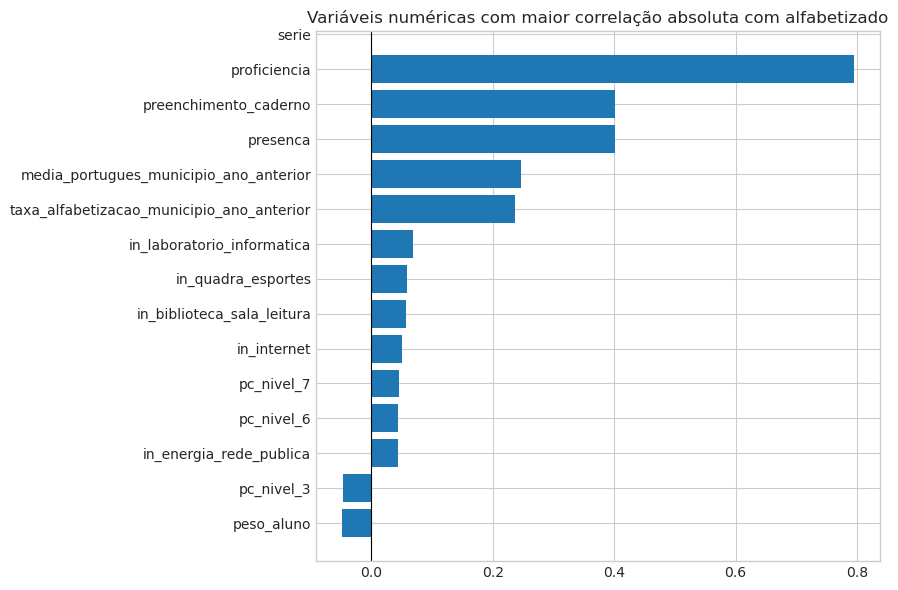

In [9]:
valores_target=lf.select(pl.col(COL_TARGET).drop_nulls().unique()).collect()[COL_TARGET].to_list(); print("Valores distintos do target:",valores_target)
if set(valores_target).issubset({0,1,0.0,1.0,True,False}) and len(valores_target)==2:
    cols_target_num=[c for c in numericas_correlacao if c in colunas]
    correlacoes=lf.select([pl.corr(pl.col(c).cast(pl.Float64),pl.col(COL_TARGET).cast(pl.Float64)).alias(c) for c in cols_target_num]).collect().row(0,named=True)
    corr_target=pl.DataFrame({"variavel":list(correlacoes),"correlacao_com_target":list(correlacoes.values())}).with_columns(pl.col("correlacao_com_target").abs().alias("abs_correlacao")).sort("abs_correlacao",descending=True)
    display(corr_target); top=corr_target.drop_nulls().head(15).sort("correlacao_com_target")
    plt.figure(figsize=(9,6)); plt.barh(top["variavel"].to_list(),top["correlacao_com_target"].to_numpy()); plt.axvline(0,color="black",linewidth=.8); plt.title("Variáveis numéricas com maior correlação absoluta com alfabetizado"); plt.tight_layout(); salvar_figura_eda(plt.gcf(),"199_8_relacao_entre_variaveis_numericas_e_o_target_01.png"); plt.show()
else: print("O target não tem exatamente dois valores binários conforme esperado.")


## 9. Comparação das variáveis numéricas por classe do target

Comparar mediana e média por classe ajuda a perceber diferenças entre alunos classificados como alfabetizados e não alfabetizados. Por ser uma base grande, a tabela agregada é preferível a um gráfico com milhões de pontos.


In [10]:
variaveis_comparacao=[nome for nome,dtype in schema.items() if dtype.is_numeric() and nome!=COL_TARGET and nome not in identificadores]
resumo_por_target=lf.group_by(COL_TARGET).agg([expr for c in variaveis_comparacao for expr in (pl.col(c).mean().alias(f"{c}_media"),pl.col(c).median().alias(f"{c}_mediana"),pl.col(c).std().alias(f"{c}_desvio_padrao"))]).sort(COL_TARGET).collect()
resumo_por_target_long=resumo_por_target.unpivot(index=COL_TARGET,variable_name="variavel_estatistica",value_name="valor").pivot(on=COL_TARGET,index="variavel_estatistica",values="valor")
display(resumo_por_target_long)


variavel_estatistica,0,1
str,f64,f64
"""ano_referencia_media""",2023.538076,2023.55787
"""ano_referencia_mediana""",2024.0,2024.0
"""ano_referencia_desvio_padrao""",0.498548,0.49664
"""serie_media""",2.0,2.0
"""serie_mediana""",2.0,2.0
…,…,…
"""in_internet_mediana""",0.992624,0.994413
"""in_internet_desvio_padrao""",0.131579,0.11599
"""in_banda_larga_media""",0.876481,0.87669


## 10. Relações com variáveis categóricas

Para evitar gráficos ilegíveis, analisamos apenas variáveis categóricas com cardinalidade baixa. As categorias são agrupadas por target e mostramos as proporções dentro de cada categoria. Códigos de alta cardinalidade e identificadores não devem ser tratados como categorias comuns.


Categóricas de baixa cardinalidade: [('rede_descricao', 3), ('dataset_split', 3)]


rede_descricao,alfabetizado,quantidade,percentual_na_categoria
str,i32,u32,f64
"""Estadual""",0,203976,46.848171
"""Estadual""",1,231422,53.151829
"""Municipal""",0,1679468,48.927336
"""Municipal""",1,1753108,51.072664
"""Privada""",0,9,36.0
"""Privada""",1,16,64.0


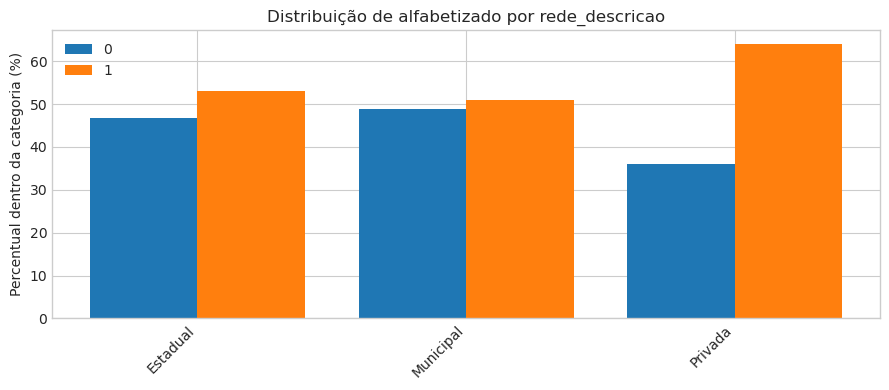

dataset_split,alfabetizado,quantidade,percentual_na_categoria
str,i32,u32,f64
"""teste""",0,282888,48.639949
"""teste""",1,298708,51.360051
"""treino""",0,1317452,48.699788
"""treino""",1,1387800,51.300212
"""validacao""",0,283113,48.71591
"""validacao""",1,298038,51.28409


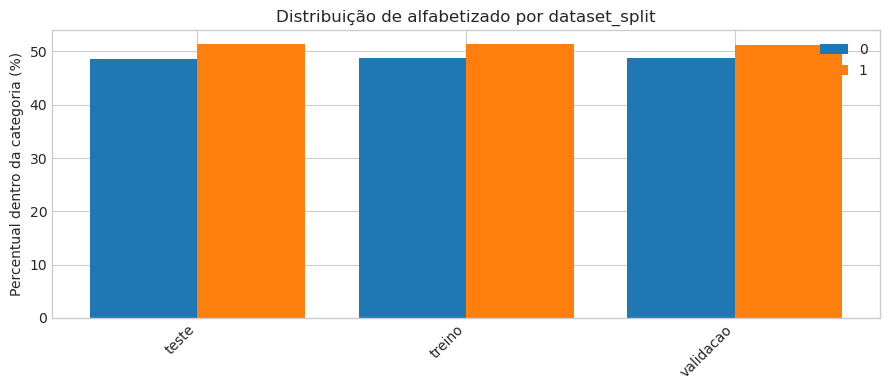

In [11]:
MAX_CATEGORIAS=12; MAX_CATEGORICAS=5; candidatas_cat=[]
for c in colunas_categoricas:
    n_cat=lf.select(pl.col(c).n_unique()).collect().item()
    if 2<=n_cat<=MAX_CATEGORIAS and c not in identificadores and c!=COL_TARGET: candidatas_cat.append((c,n_cat))
print("Categóricas de baixa cardinalidade:",candidatas_cat)
for c,n_cat in candidatas_cat[:MAX_CATEGORICAS]:
    tab=(lf.group_by([c,COL_TARGET]).agg(pl.len().alias("quantidade")).collect().with_columns((100*pl.col("quantidade")/pl.col("quantidade").sum().over(c)).alias("percentual_na_categoria")).sort([c,COL_TARGET]))
    display(tab); pivot=tab.pivot(on=COL_TARGET,index=c,values="percentual_na_categoria").fill_null(0); classes=[x for x in pivot.columns if x!=c]; x=np.arange(pivot.height); largura=.8/max(1,len(classes)); plt.figure(figsize=(9,4))
    for j,classe in enumerate(classes): plt.bar(x+j*largura,pivot[classe].to_numpy(),width=largura,label=str(classe))
    plt.xticks(x+largura*(len(classes)-1)/2,pivot[c].cast(pl.String).to_list(),rotation=45,ha="right"); plt.title(f"Distribuição de alfabetizado por {c}"); plt.ylabel("Percentual dentro da categoria (%)"); plt.legend(); plt.tight_layout(); salvar_figura_eda(plt.gcf(),"203_10_relacoes_com_variaveis_categoricas_01.png"); plt.show()


## 11. Inspeção de relações específicas

Use esta seção para investigar hipóteses levantadas nos gráficos. Por exemplo, compare indicadores socioeconômicos, infraestrutura escolar e contexto municipal. Ajuste os nomes conforme as colunas reais impressas na seção 2.

A tabela abaixo permite verificar se nomes de variáveis de interesse estão presentes sem gerar erro caso algum deles não exista.


In [12]:
variaveis_interesse = [
    "media_inse",
    "valor_pib_per_capita",
    "valor_fundeb",
    "valor_receitas",
    "taxa_alfabetizacao_municipio_ano_anterior",
    "media_portugues_municipio_ano_anterior",
    "proficiencia",
    "peso_aluno",
]
presentes = [c for c in variaveis_interesse if c in colunas]
ausentes = [c for c in variaveis_interesse if c not in colunas]

print("Variáveis de interesse presentes:", presentes)
print("Variáveis de interesse não encontradas:", ausentes)


Variáveis de interesse presentes: ['media_inse', 'valor_pib_per_capita', 'valor_fundeb', 'valor_receitas', 'taxa_alfabetizacao_municipio_ano_anterior', 'media_portugues_municipio_ano_anterior', 'proficiencia', 'peso_aluno']
Variáveis de interesse não encontradas: []


## 12. Registro dos principais achados

Preencha esta seção após executar e interpretar os resultados. Evite registrar apenas valores de correlação: descreva o padrão observado, a limitação e o que precisa ser verificado.


In [13]:
achados = pl.DataFrame([
    {
        "tema": "Distribuição do target",
        "observacao": (
            "As classes estão relativamente equilibradas: "
            "51,31% dos registros pertencem à classe 1 e 48,69% à classe 0."
        ),
        "limitacao/validacao": (
            "A classificação foi recebida pronta na base original. "
            "Sua regra de construção não foi reproduzida neste notebook."
        )
    },
    {
        "tema": "Relações entre variáveis numéricas",
        "observacao": (
            "Foram identificadas correlações elevadas entre algumas "
            "variáveis de volume e estrutura educacional, indicando "
            "possível sobreposição de informações."
        ),
        "limitacao/validacao": (
            "A correlação de Pearson identifica principalmente relações "
            "lineares e não comprova causalidade."
        )
    },
    {
        "tema": "Relações com o target",
        "observacao": (
            "As maiores correlações positivas foram observadas em "
            "proficiencia (0,795599), preenchimento_caderno (0,401542), "
            "presenca (0,401007), media_portugues_municipio_ano_anterior "
            "(0,246996) e taxa_alfabetizacao_municipio_ano_anterior (0,235955)."
        ),
        "limitacao/validacao": (
            "As associações não comprovam causalidade. A relação entre "
            "proficiencia e alfabetizado deve ser avaliada antes da "
            "modelagem para verificar possível vazamento de informação."
        )
    },
    {
        "tema": "Variáveis categóricas",
        "observacao": (
            "As proporções das classes são semelhantes nas redes estadual "
            "e municipal. Na rede privada, 64% dos registros pertencem "
            "à classe 1."
        ),
        "limitacao/validacao": (
            "A rede privada possui apenas 25 registros, quantidade "
            "insuficiente para conclusões robustas. dataset_split é "
            "uma variável de controle, não um preditor."
        )
    },
    {
        "tema": "Valores ausentes e cobertura temporal",
        "observacao": (
            "As análises anteriores identificaram valores ausentes em "
            "parte das variáveis da base."
        ),
        "limitacao/validacao": (
            "A cobertura e a disponibilidade temporal devem ser verificadas "
            "antes da seleção das variáveis para modelagem."
        )
    },
    {
        "tema": "Possível redundância entre variáveis",
        "observacao": (
            "A matriz de correlação mostrou associações elevadas entre "
            "algumas variáveis relacionadas a quantidades de escolas, "
            "alunos e estrutura educacional."
        ),
        "limitacao/validacao": (
            "É necessário avaliar a sobreposição de informações e o "
            "significado das variáveis antes de selecionar as features."
        )
    },
    {
        "tema": "Possível data leakage",
        "observacao": (
            "A elevada correlação entre proficiencia e alfabetizado "
            "merece investigação antes da construção dos modelos."
        ),
        "limitacao/validacao": (
            "A correlação, isoladamente, não comprova vazamento. "
            "É necessário avaliar a origem das variáveis e sua "
            "disponibilidade no momento da previsão."
        )
    }
])

display(achados)


tema,observacao,limitacao/validacao
str,str,str
"""Distribuição do target""","""As classes estão relativamente…","""A classificação foi recebida p…"
"""Relações entre variáveis numér…","""Foram identificadas correlaçõe…","""A correlação de Pearson identi…"
"""Relações com o target""","""As maiores correlações positiv…","""As associações não comprovam c…"
"""Variáveis categóricas""","""As proporções das classes são …","""A rede privada possui apenas 2…"
"""Valores ausentes e cobertura t…","""As análises anteriores identif…","""A cobertura e a disponibilidad…"
"""Possível redundância entre var…","""A matriz de correlação mostrou…","""É necessário avaliar a sobrepo…"
"""Possível data leakage""","""A elevada correlação entre pro…","""A correlação, isoladamente, nã…"


## 13. Conclusão

As análises exploratórias realizadas neste notebook permitiram investigar as relações entre as variáveis da base consolidada e o target `alfabetizado`, complementando as análises de distribuição e de valores ausentes realizadas anteriormente.

A análise de correlação identificou associações positivas entre `alfabetizado` e as variáveis `proficiencia`, `preenchimento_caderno`, `presenca`, `media_portugues_municipio_ano_anterior` e `taxa_alfabetizacao_municipio_ano_anterior`. Entre elas, `proficiencia` apresentou a maior correlação. Esses resultados contribuem para identificar relações que merecem investigação nas próximas etapas, mas não comprovam causalidade.

A comparação entre as classes do target também mostrou diferenças nas médias de algumas variáveis educacionais. Na análise das variáveis categóricas, as proporções das classes foram semelhantes nas redes estadual e municipal. Os resultados da rede privada devem ser interpretados com cautela, devido à pequena quantidade de registros observados.

A interpretação dos resultados deve considerar os valores ausentes, a cobertura temporal e a possível redundância entre variáveis. A relação entre `proficiencia` e `alfabetizado` também requer atenção antes da modelagem, para avaliar a origem das informações e o possível risco de *data leakage*.

Conclui-se que o TC3-46 contribui para o entendimento inicial das relações presentes na base e fornece subsídios para as próximas etapas do projeto. A seleção definitiva das variáveis para os modelos deverá considerar sua qualidade, seu significado, sua disponibilidade no momento da previsão e sua adequação aos objetivos de negócio.
